In [1]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import pickle
from scipy.stats import linregress
import os
import sys
from datetime import date
from sklearn.metrics import auc, f1_score
import random
from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize
from mpl_toolkits.axes_grid1 import axes_grid
import mpl_scatter_density
from matplotlib.colors import LinearSegmentedColormap

**load data**

In [2]:
# #saving only the added delta values and biosample/DHS inds
# for i in range(2, 11):
#     print(i)
#     #load npz file
#     filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_diffflat_sorteddiffbiosample_sorteddiffdhs_fillsize100_cycle'+str(i)+'_CT20220224.npz'
#     cycle_np_file = np.load(filename)
    
#     #load biosample and DHS inds
#     cycle_sorted_diff_DHS_inds = cycle_np_file['sorted_diff_DHS_inds']
#     cycle_sorted_diff_biosample_inds = cycle_np_file['sorted_diff_biosample_inds']
    
#     #find number of DHSs
#     n_DHSs = int(len(cycle_sorted_diff_DHS_inds)/733)
    
#     #recreate flat indices
#     cycle_sorted_diff_flat_inds = np.int64(cycle_sorted_diff_DHS_inds) + (n_DHSs * np.int64(cycle_sorted_diff_biosample_inds))
    
#     #take the 100 added flat indices
#     added_100_flat_inds = cycle_sorted_diff_flat_inds[-100:]
#     del cycle_sorted_diff_flat_inds

#     cycle_diff_flat_array = cycle_np_file['diff_flat_array']

#     added_100_delta_vals = np.flip(cycle_diff_flat_array[added_100_flat_inds])
#     added_100_DHS_inds = np.flip(cycle_sorted_diff_DHS_inds[-100:])
#     added_100_biosample_inds = np.flip(cycle_sorted_diff_biosample_inds[-100:])

#     outfile = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_diffflat_sorteddiffbiosample_sorteddiffdhs_fillsize100_cycle'+str(i)+'_addedonly_CT20220224.npz'
#     np.savez(outfile, delta_vals=added_100_delta_vals, DHS_inds=added_100_DHS_inds, biosample_inds=added_100_biosample_inds)
    
#     del added_100_delta_vals
#     del added_100_DHS_inds
#     del added_100_biosample_inds
#     del cycle_diff_flat_array
#     del cycle_sorted_diff_DHS_inds
#     del cycle_sorted_diff_biosample_inds

In [3]:
#load npz file
delta_vals_all_cycles = []
DHS_inds_all_cycles = []
biosample_inds_all_cycles = []

for i in range(1, 11):
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_diffflat_sorteddiffbiosample_sorteddiffdhs_fillsize100_cycle'+str(i)+'_addedonly_CT20220224.npz'
    cycle_np_file = np.load(filename)
    delta_vals_all_cycles.append(cycle_np_file['delta_vals'])
    DHS_inds_all_cycles.append(cycle_np_file['DHS_inds'])
    biosample_inds_all_cycles.append(cycle_np_file['biosample_inds'])
    
delta_vals_all_cycles = np.array(delta_vals_all_cycles)
DHS_inds_all_cycles = np.array(DHS_inds_all_cycles)
biosample_inds_all_cycles = np.array(biosample_inds_all_cycles)

In [2]:
#read in 733 sample x 3.5+ million DHS presence/absence matrix
dhs = pd.read_table('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38.txt.gz', header=None).T
print(dhs.shape)
dhs_array = dhs.to_numpy().astype(bool)
# np.save('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38_bool_array.npy', dhs_array)
del dhs

(733, 3591898)


In [9]:
file = '/home/ctrader/NMF_data/DHS_signal_matrix/DHS_peak_signal_hg38.75_20.normalized.GRCh38_no_alts_array_CT20220215.npy'
DHS_peak_signal_array = np.load(file)

In [5]:
n_biosamples, n_DHSs = DHS_peak_signal_array.shape

In [41]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])
DHS_metadata['mean_signal'] = DHS_metadata['mean_signal'].astype(float)

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


**Removing 1 to 1 interactions**

In [5]:
filtered_biosample_inds_all_cycles = []
filtered_DHS_inds_all_cycles = []
filtered_delta_vals_all_cycles = []

for i in range(10):
    print(i)
    #when i=0, that is referring to cycle 1 in biosample, DHS, and delta arrays, and we want to compare to 
    #the previous cycle (original) array value
    if i==0:
        #read in 733 sample x 3.5+ million DHS presence/absence matrix
        dhs_arr = np.load('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38_bool_array.npy')
        
    #when i=1, that is referring to cycle 2 in biosample, DHS, and delta arrays, and we want to compare to 
    #the previous cycle (cycle 1) array value
    else:
        filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_booldhsarr_basis_mixture_fillsize100_cycle'+str(i)+'_CT20220224.npz'
        np_file = np.load(filename)
        dhs_arr = np_file['new_dhs_array']
        
    biosample_inds_single_cycle = []
    DHS_inds_single_cycle = []
    delta_vals_single_cycle = []
    
    #when i=1, that is referring to cycle 2 in biosample, DHS, and delta arrays, and we want to compare to 
    #the previous cycle (cycle 1) array value
    for biosample, dhs, delta in zip(biosample_inds_all_cycles[i, :], DHS_inds_all_cycles[i, :], delta_vals_all_cycles[i, :]):
        if ~dhs_arr[biosample, dhs]:
            biosample_inds_single_cycle.append(biosample)
            DHS_inds_single_cycle.append(dhs)
            delta_vals_single_cycle.append(delta)
    
    del dhs_arr
    filtered_biosample_inds_all_cycles.append(np.array(biosample_inds_single_cycle))
    filtered_DHS_inds_all_cycles.append(np.array(DHS_inds_single_cycle))
    filtered_delta_vals_all_cycles.append(delta_vals_single_cycle)

0
1
2
3
4
5
6
7
8
9


In [34]:
print('Percent of calls changed from 1 to 1 in cycle 1: %s' %((1-len(first_01_added_calls_previously_0)/len(first_01_added_calls_biosample_inds))*100))
print('Percent of calls changed from 1 to 1 in cycle 2: %s' %((1-len(second_01_added_calls_previously_0)/len(second_01_added_calls_biosample_inds))*100))
print('Percent of calls changed from 1 to 1 in cycle 3: %s' %((1-len(third_01_added_calls_previously_0)/len(third_01_added_calls_biosample_inds))*100))

Percent of calls changed from 1 to 1 in cycle 1: 2.811011599553337
Percent of calls changed from 1 to 1 in cycle 2: 4.255828262801664
Percent of calls changed from 1 to 1 in cycle 3: 5.251323655644436


Text(0.5, 1.0, 'Delta Values for Added (Previously 0) Calls from Each Cycle\nDelta Flip, Flip Size=100')

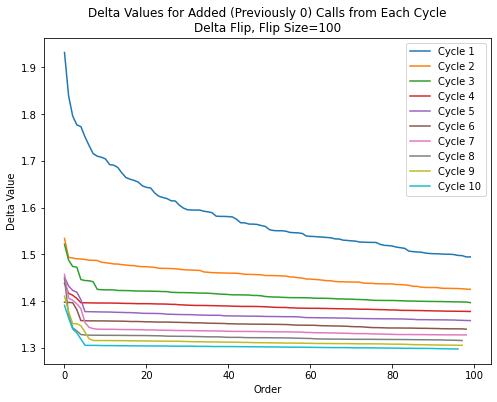

In [8]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

for i in range(10):
    plt.plot(np.arange(len(filtered_delta_vals_all_cycles[i])), filtered_delta_vals_all_cycles[i])


plt.legend(['Cycle 1', 'Cycle 2', 'Cycle 3', 'Cycle 4', 'Cycle 5', 'Cycle 6', 'Cycle 7', 'Cycle 8', 'Cycle 9', 'Cycle 10'])

plt.xlabel('Order')
plt.ylabel('Delta Value')
plt.title('Delta Values for Added (Previously 0) Calls from Each Cycle\nDelta Flip, Flip Size=100')

**Plotting delta vs peak signal and peak signal vs mean signal for removed calls**

In [15]:
#finding peak signal values of removed calls
filtered_peak_signal_all_cycles = []
for i in range(10):
    print(i)
    peak_signal_single_cycle = []
    for biosample, dhs in zip(filtered_biosample_inds_all_cycles[i], filtered_DHS_inds_all_cycles[i]):
        peak_signal_single_cycle.append(DHS_peak_signal_array[biosample, dhs])
    peak_signal_single_cycle = np.array(peak_signal_single_cycle)
    filtered_peak_signal_all_cycles.append(peak_signal_single_cycle)

0
1
2
3
4
5
6
7
8
9


Text(0.5, 1.0, 'Comparing Delta Values to DHS Peak Signal for Added (Previously 0) Calls\nDelta Flip, Flip Size=100')

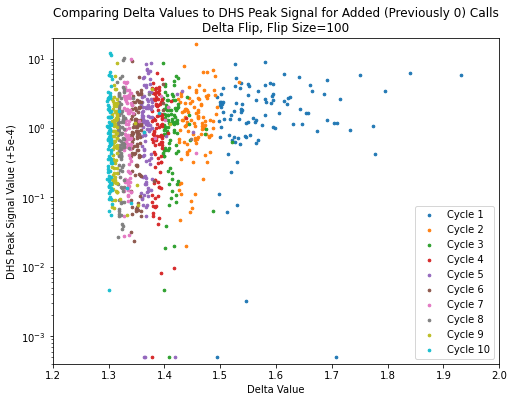

In [40]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

for i in range(10):
    plt.scatter(filtered_delta_vals_all_cycles[i], filtered_peak_signal_all_cycles[i]+0.0005, s=7)
    plt.xlim([1.2, 2])
    plt.ylim([0.0004, 20])
    plt.yscale('log')
    
plt.legend(['Cycle 1', 'Cycle 2', 'Cycle 3', 'Cycle 4', 'Cycle 5', 'Cycle 6', 'Cycle 7', 'Cycle 8', 'Cycle 9', 'Cycle 10'])

plt.xlabel('Delta Value')
plt.ylabel('DHS Peak Signal Value (+5e-4)')
plt.title('Comparing Delta Values to DHS Peak Signal for Added (Previously 0) Calls\nDelta Flip, Flip Size=100')

In [42]:
#finding average signal value of DHS of removed calls
filtered_mean_signal_all_cycles = []
for i in range(10):
    mean_signal_vals_single_cycle = np.array(DHS_metadata.loc[filtered_DHS_inds_all_cycles[i]]['mean_signal'])
    filtered_mean_signal_all_cycles.append(mean_signal_vals_single_cycle)

In [48]:
for i in filtered_peak_signal_all_cycles:
    print(np.max(i))

8.89899
15.9433
8.65546
6.15328
8.72956
9.33129
9.78956
10.3193
8.56515
11.9353


Text(0.5, 1.07, 'Comparing DHS Peak Signal for Added (Previously 0) Calls to Mean Signal of Corresponding DHS\nDelta Flip, Flip Size=100')

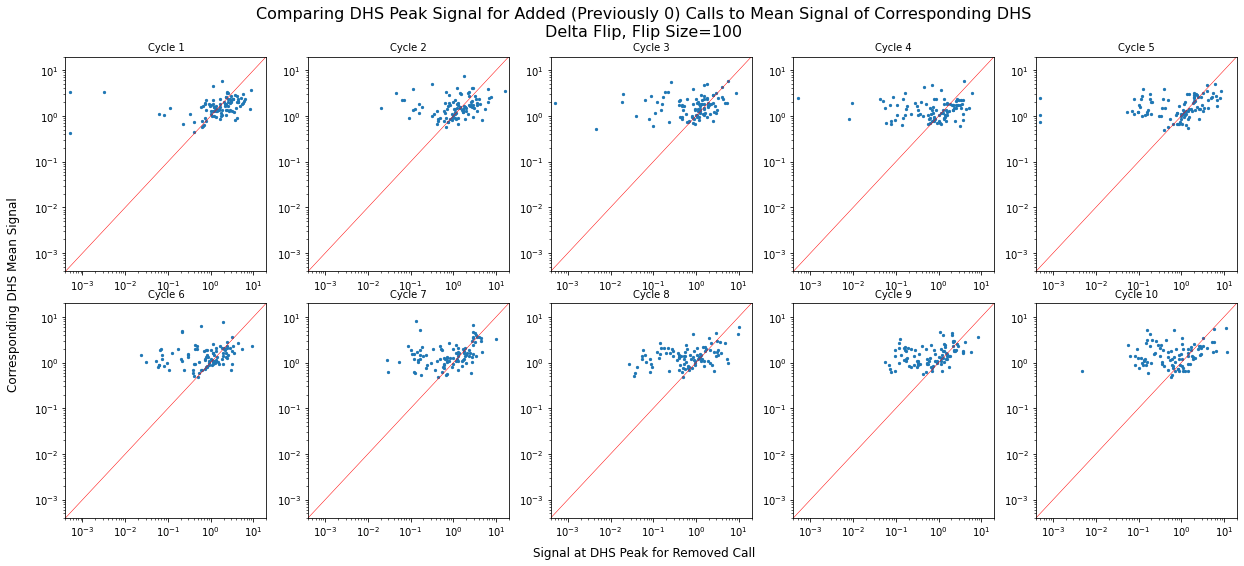

In [54]:
fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(17,7))
fig.patch.set_facecolor('white')
fig.tight_layout()

axes = axes.ravel()
for ax, i in zip(axes, range(10)):
    scat = ax.scatter(filtered_peak_signal_all_cycles[i]+0.0005, filtered_mean_signal_all_cycles[i], s=5)
    ax.set_title('Cycle ' + str(i+1), fontsize=10)
    ax.set_xlim([0.0004, 20])
    ax.set_ylim([0.0004, 20])
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.plot(np.arange(300)-1, np.arange(300)-1, c='r', linewidth=0.5)
    
# plt.legend(['First 1000 removed Calls', 'Last 1000 removed Calls'])
fig.text(0.5, -0.02, 'Signal at DHS Peak for Removed Call', ha='center', fontsize=12)
fig.text(-0.02, 0.5, 'Corresponding DHS Mean Signal', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing DHS Peak Signal for Added (Previously 0) Calls to Mean Signal of Corresponding DHS\nDelta Flip, Flip Size=100', fontsize=16, x=0.5, y=1.07)